This script looks at how similar children's utterances are to adults over time

In [1]:
library(tidyverse)
library(viridis)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.6
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Loading required package: viridisLite



In [2]:
utterances <- read_csv("../data/tidy/utterances.csv") %>%
  filter(utterance_exists == 1, utterance_interference == 0)

Rows: 638 Columns: 30
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (10): participant_id, target_category, utterance_ns, utterance_masked, u...
dbl (18): age_months, age_yrs, utterance_exists, utterance_interference, utt...
lgl  (2): is_adult, is_child

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [3]:
sea_animal_categories <- c("crab", "octopus", "shark", "whale", "turtle", "seahorse")


In [4]:
utterances_plot <- utterances %>%
  filter(str_starts(participant_id, "BD")) %>%
  mutate(
    target_category = str_trim(str_to_lower(target_category))
  ) %>%
  filter(target_category %in% sea_animal_categories) %>%
  select(
    participant_id,
    age_months,
    target_category,
    utterance_half_cossim_adults,
    utterance_full_cossim_adults
  ) %>%
  pivot_longer(
    cols = c(utterance_half_cossim_adults, utterance_full_cossim_adults),
    names_to = "utterance_timepoint",
    values_to = "cosine_similarity_to_adults"
  ) %>%
  mutate(
    utterance_timepoint = recode(
      utterance_timepoint,
      utterance_half_cossim_adults = "50% utterance",
      utterance_full_cossim_adults = "100% utterance"
    ),
    utterance_timepoint = factor(
      utterance_timepoint,
      levels = c("50% utterance", "100% utterance")
    ),
    age_yrs = age_months / 12
  ) %>%
  group_by(target_category) %>%
  mutate(
    cossim_z = (cosine_similarity_to_adults - mean(cosine_similarity_to_adults, na.rm = TRUE)) /
                                    sd(cosine_similarity_to_adults, na.rm = TRUE)
  ) %>%
  ungroup()

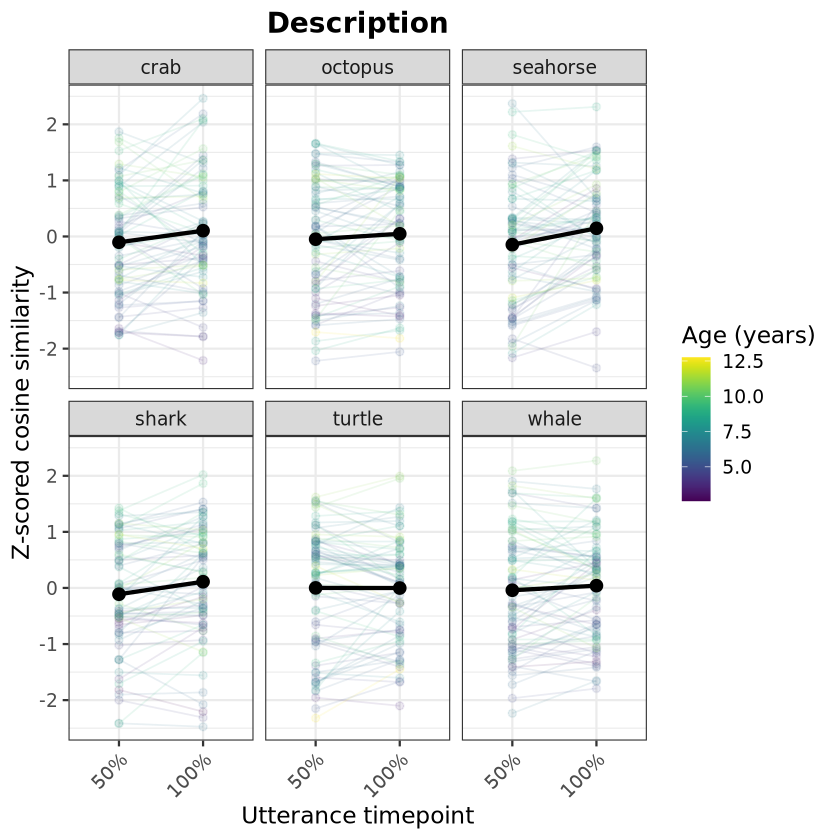

In [15]:
ggplot(
  utterances_plot,
  aes(
    x = utterance_timepoint,
    y = cossim_z,
    group = interaction(participant_id, target_category),
    color = age_yrs
  )
) +
  geom_line(alpha = 0.1, linewidth = 0.5) +
  geom_point(alpha = 0.1, size = 1.8) +
  stat_summary(aes(group = 1), fun = mean, geom = "line", color = "black", linewidth = 1.2) +
  stat_summary(aes(group = 1), fun = mean, geom = "point", color = "black", size = 3) +
  facet_wrap(~ target_category) +
  scale_color_viridis(
    name = "Age (years)",
    option = "viridis"
  ) +
  scale_x_discrete(labels = c("50% utterance" = "50%", "100% utterance" = "100%")) +
  labs(
    title = "Description",
    x = "Utterance timepoint",
    y = "Z-scored cosine similarity"
  ) +
  theme_bw(base_size = 14) +
  theme(
    plot.title = element_text(hjust = 0.5, face = "bold"),
    axis.text.x = element_text(angle = 45, hjust = 1)
  )
ggsave("../figures/utterance_similarity_to_adults_over_time.png", width = 6, height = 8, dpi = 300)

In [6]:
library(lme4)
library(lmerTest)

utterances_plot$utterance_timepoint <- factor(
  utterances_plot$utterance_timepoint,
  levels = c("50% utterance", "100% utterance")
)

utterance_time_model <- lmer(
  cossim_z ~ utterance_timepoint + scale(age_months) +
    (1 | participant_id),
  data = utterances_plot
)

summary(utterance_time_model)

Loading required package: Matrix


Attaching package: ‘Matrix’


The following objects are masked from ‘package:tidyr’:

    expand, pack, unpack



Attaching package: ‘lmerTest’


The following object is masked from ‘package:lme4’:

    lmer


The following object is masked from ‘package:stats’:

    step




Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: 
cossim_z ~ utterance_timepoint + scale(age_months) + (1 | participant_id)
   Data: utterances_plot

REML criterion at convergence: 2204.2

Scaled residuals: 
     Min       1Q   Median       3Q      Max 
-3.02869 -0.63570  0.05361  0.67339  2.94051 

Random effects:
 Groups         Name        Variance Std.Dev.
 participant_id (Intercept) 0.2426   0.4926  
 Residual                   0.6840   0.8270  
Number of obs: 844, groups:  participant_id, 79

Fixed effects:
                                   Estimate Std. Error        df t value
(Intercept)                        -0.10270    0.06923  99.27388  -1.483
utterance_timepoint100% utterance   0.14759    0.05694 757.46976   2.592
scale(age_months)                   0.28894    0.06086  74.07643   4.748
                                  Pr(>|t|)    
(Intercept)                        0.14115    
utterance_timepoint100% utterance  0.00972 ** 
sc

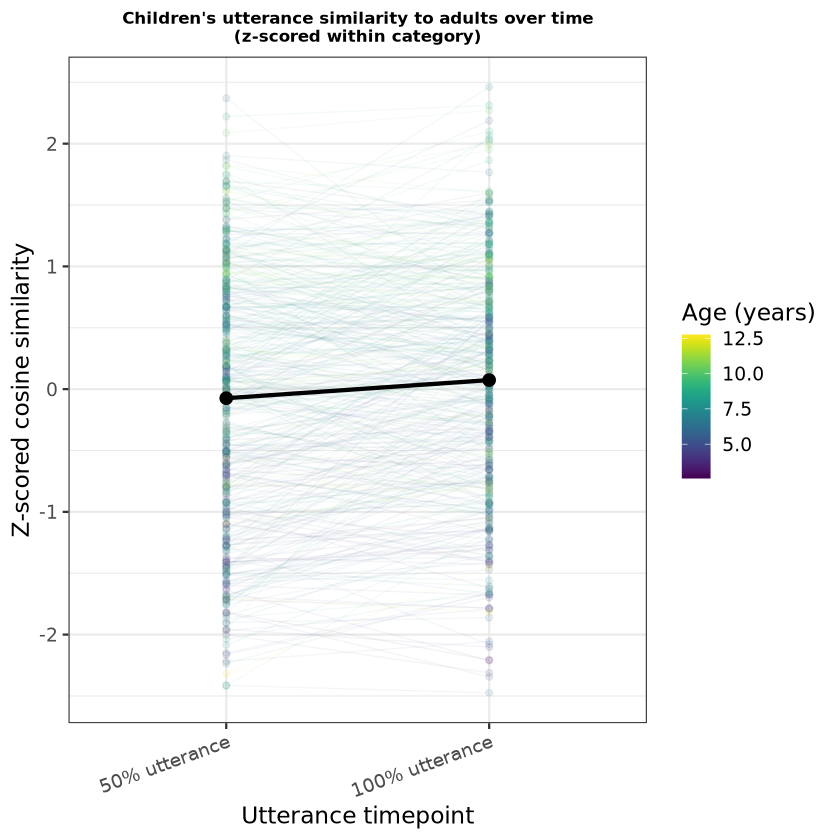

In [7]:
#Fig 11B
ggplot(
  utterances_plot,
  aes(
    x = utterance_timepoint,
    y = cossim_z,
    group = interaction(participant_id, target_category),
    color = age_yrs
  )
) +
  geom_line(alpha = 0.05, linewidth = 0.4) +
  geom_point(alpha = 0.1, size = 1.5) +
  #facet_wrap(~ target_category) +
  scale_color_viridis(
    name = "Age (years)",
    option = "viridis"
  ) +
    stat_summary(
    aes(group = 1),
    fun = mean,
    geom = "line",
    color = "black",
    linewidth = 1.2
  ) +
  stat_summary(
    aes(group = 1),
    fun = mean,
    geom = "point",
    color = "black",
    size = 3
  ) +
  labs(
    title = "Children's utterance similarity to adults over time\n(z-scored within category)",
    x = "Utterance timepoint",
    y = "Z-scored cosine similarity"
  ) +
  theme_bw(base_size = 14) +
  theme(
    plot.title = element_text(hjust = 0.5, face = "bold", size = 10),
    axis.text.x = element_text(angle = 20, hjust = 1)
  )

  ggsave("../figures/collapsed_utterance_similarity_to_adults_over_time.png",
         width = 5,
         height = 5,
         dpi = 300)

In [8]:
utterances_plot <- utterances_plot %>%
  mutate(
    age_bin = ntile(age_yrs, 6),
    age_bin = factor(age_bin)
  ) %>%
  group_by(age_bin) %>%
  mutate(
    age_bin_label = paste0(
      round(min(age_yrs), 1), "–", round(max(age_yrs), 1)
    )
  ) %>%
  ungroup() %>%
  mutate(age_bin_label = factor(age_bin_label, levels = unique(age_bin_label[order(age_bin)])))

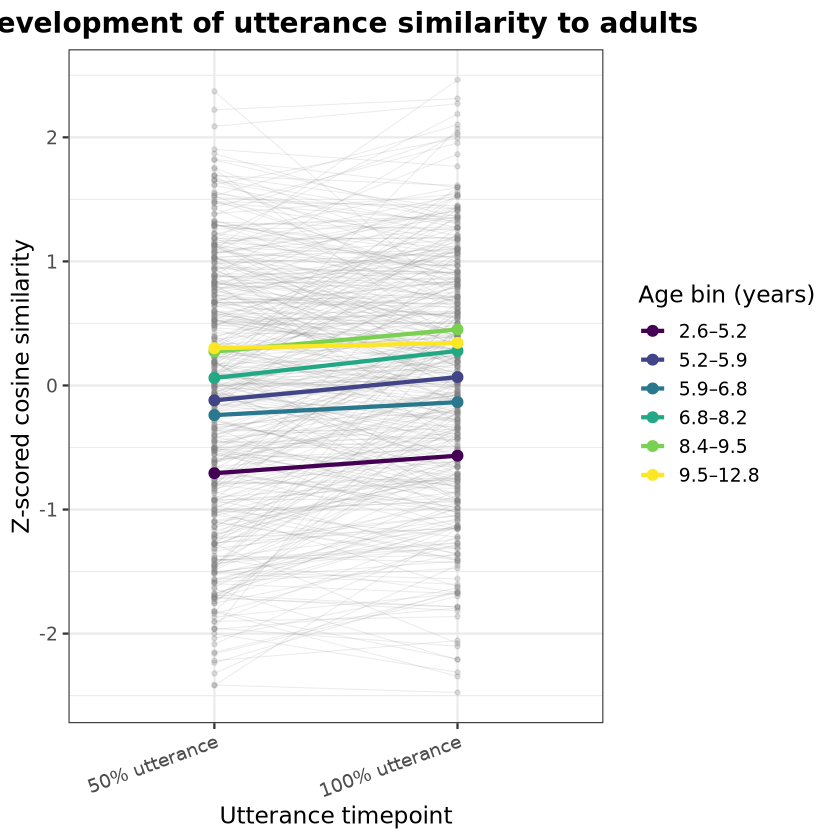

In [9]:
ggplot(
  utterances_plot,
  aes(
    x = utterance_timepoint,
    y = cossim_z,
    group = interaction(participant_id, target_category),
    color = age_bin_label
  )
) +
  geom_line(alpha = 0.15, linewidth = 0.3, color = "grey50") +
  geom_point(alpha = 0.2, size = 1, color = "grey50") +

  stat_summary(
    aes(color = age_bin_label, group = age_bin_label),
    fun = mean,
    geom = "line",
    linewidth = 1.2
  ) +
  stat_summary(
    aes(color = age_bin_label, group = age_bin_label),
    fun = mean,
    geom = "point",
    size = 2.5
  ) +

  scale_color_viridis_d(
    name = "Age bin (years)",
    option = "viridis"
  ) +

  labs(
    title = "Development of utterance similarity to adults",
    x = "Utterance timepoint",
    y = "Z-scored cosine similarity"
  ) +

  theme_bw(base_size = 14) +
  theme(
    plot.title = element_text(hjust = 0.5, face = "bold"),
    axis.text.x = element_text(angle = 20, hjust = 1)
  )

  ggsave(
    "../figures/utterance_similarity_to_adults_over_time_by_age_bin.png",
    width = 10,
    height = 6,
    dpi = 300
  )

In [10]:
utterance_model <- lmer(
  cossim_z ~ utterance_timepoint * scale(age_months) +
    (1 | participant_id),
  data = utterances_plot
)

In [11]:
summary(utterance_model)

Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: 
cossim_z ~ utterance_timepoint * scale(age_months) + (1 | participant_id)
   Data: utterances_plot

REML criterion at convergence: 2207.9

Scaled residuals: 
     Min       1Q   Median       3Q      Max 
-3.04439 -0.63667  0.05276  0.67236  2.94227 

Random effects:
 Groups         Name        Variance Std.Dev.
 participant_id (Intercept) 0.2425   0.4925  
 Residual                   0.6848   0.8275  
Number of obs: 844, groups:  participant_id, 79

Fixed effects:
                                                     Estimate Std. Error
(Intercept)                                          -0.10268    0.06924
utterance_timepoint100% utterance                     0.14759    0.05697
scale(age_months)                                     0.29901    0.06720
utterance_timepoint100% utterance:scale(age_months)  -0.02012    0.05700
                                                           df t value 

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


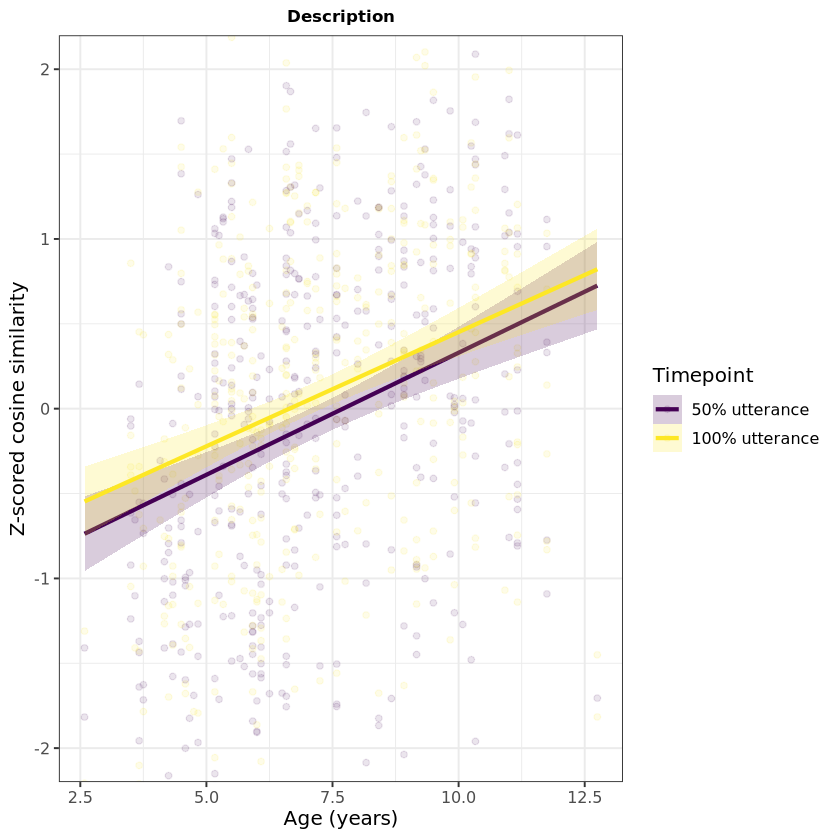

In [13]:
#Fig 12B
ggplot(utterances_plot, aes(
  x = age_months/12,
  y = cossim_z,
  color = utterance_timepoint,
  fill = utterance_timepoint
)) +
  geom_point(alpha = 0.1, size = 1.5) +
  geom_smooth(method = "lm", se = TRUE, linewidth = 1.2, alpha = 0.2) +
  scale_color_viridis_d(name = "Timepoint") +
  scale_fill_viridis_d(name = "Timepoint") +
  coord_cartesian(ylim = c(-2, 2)) +
  labs(
    x = "Age (years)",
    y = "Z-scored cosine similarity",
    title = "Description"
  ) +
  theme_bw(base_size = 12) +
  theme(plot.title = element_text(hjust = 0.5, face = "bold", size = 10))

ggsave(
  "../figures/utterance_similarity_to_adults_over_time_interaction_plot.png",
  width = 5,
  height = 6,
  dpi = 300
)